# Molecular dynamics of liquid argon

864 Lennard-Jones particles in a periodic box (rho = 0.75, reduced units). First relax the random starting positions, then run velocity Verlet and rescale the velocities a few times to get to the target temperature. After that I check energy conservation, compare the speeds to Maxwell-Boltzmann, look at the pair separation histogram, and get the pressure from the virial.

The MD run saves a `.npz` file. Those files aren't in the repo (too big), so change `file_path` to your own run.

In [1]:
import numpy as np

# KE, T, F, U, Relaxation Helpers

def kin_energy(vel):
    return 24.0 * np.sum(vel * vel)

def temp(vel,N):
    return (16.0 / N) * np.sum(vel * vel)

def r_ij_matrix(pos, L):
    Nloc = pos.shape[0]
    d = pos.reshape(Nloc, 1, 3) - pos.reshape(1, Nloc, 3)
    d -= L * np.around(d / L)  
    return d

def net_force(pos, L):
    d  = r_ij_matrix(pos, L)                # (N,N,3)
    r2 = np.sum(d * d, axis=2)              # (N,N)
    np.fill_diagonal(r2, np.inf)            # kill diagonal
    invr2   = 1.0 / r2
    f_scale = (invr2**7) - 0.5*(invr2**4)   # (N,N)
    F = np.sum(d * f_scale[:, :, None], axis=1)   # (N,3)
    return F

def pot_energy(pos, L):
    d  = r_ij_matrix(pos, L)
    r2 = np.sum(d * d, axis=2)
    np.fill_diagonal(r2, np.inf)
    iu = np.triu_indices(pos.shape[0], k=1)     # i<j
    invr2 = 1.0 / r2[iu]
    invr6  = invr2**3
    u_pairs = 4.0 * (invr6**2 - invr6)
    return np.sum(u_pairs)

def relax(pos, vel,L, step=1e-2, n_steps=10000):

    E = pot_energy(pos, L)
    for i in range(n_steps):
        F = net_force(pos, L)
        F_unit  = unit_force(F)


        pos = (pos + step * F_unit) % L     
        E = pot_energy(pos, L)
    
                              

        if E < -1000:
            break
        if i % 10==0:
            print("PE:", E)
    print("Final PE:", E)
    print("Total Energy: ", E + kin_energy(vel))
    return pos
def unit_force(F, tol=1e-12):
    mag = np.linalg.norm(F, axis=1, keepdims=True)
    F_unit = np.divide(F, mag, out=np.zeros_like(F), where=mag > tol)
    return F_unit


In [45]:
# RELAXATION STEPS BEFORE MD
N = 864
rho = 0.75
L = (N / rho) ** (1/3)

pos = np.random.uniform(0.0, L, size=(N, 3))
a = 0.1
vel = np.random.uniform(-a, a, size=(N, 3))

vel_initial = vel - vel.mean(axis=0)

pos_relaxed = relax(pos,vel_initial,L)
print("T_initial:  ", temp(vel_initial,N))

PE: 27385484665482.406
PE: 35450325.321906686
PE: 234378.04674048556
PE: 14102.758683049804
Final PE: -1231.1340736449833
Total Energy:  -1023.2063332792691
T_initial:   0.1604380712698412


In [6]:
# MD FUNCTION, rescales KE to get T_target every 100 steps 10 times (optional), 1200 total steps, SAVES pos,vel,forces,KE,PE,TE to file

from datetime import datetime
# assume already relaxed or from file

def md_verlet(pos, vel, L, N  = 864, T_target=1.069, n_steps=1000,tau=0.01,rescale = True,rescale_interval=100, num_rescales = 10, save_interval=1,saving=False,file_name="MD_results",verbose=True):

    pos = pos.copy()
    vel = vel.copy()

    PE_init = pot_energy(pos, L)
    KE_init  = kin_energy(vel)
    PEs, KEs, TEs = [PE_init], [KE_init], [PE_init+KE_init]
    
    steps = [0]
    pos_snaps = [pos.copy()]
    vel_snaps = [vel.copy()]
    print(f"step 0  PE={PE_init: .6f}  KE={KE_init: .6f}  E={(PE_init+KE_init): .6f}")

    F = net_force(pos, L)
    Forces = [F]
    steps_to_target = None
    nres = 0
    for step in range(1, n_steps + 1):
        # x_{n+1}
        pos = (pos + vel * tau + 0.5 * F * tau ** 2) % L

        # F_{n+1}
        F_new = net_force(pos, L)
        # v_{n+1}
        vel = vel + 0.5 * (F + F_new) * tau
        F = F_new
        # rescale KE every rescale_interval steps to rech T_target
        if rescale  and ((step) % rescale_interval == 1) and step // rescale_interval and nres < num_rescales:
            T_curr = temp(vel,N)  
            if round(T_curr, 3) != round(T_target, 3):
                s = np.sqrt(T_target / T_curr)
                vel *= s
                T_new = temp(vel,N)
                nres += 1
                if verbose:
                    print(f"step {step} (rescale {step // rescale_interval}) "
                          f"T_curr={T_curr:.6f} -> T_new={T_new:.6f}")
            else:
                if verbose:
                    print(f"step {step} T is on target: {T_curr:.6f}")

        if save_interval and (step % save_interval == 0):
            pos_snaps.append(pos.copy())
            vel_snaps.append(vel.copy())
            Forces.append(F_new.copy())
            PE = pot_energy(pos, L)
            KE = kin_energy(vel)  # your 24*sum(v^2) convention
            PEs.append(PE); KEs.append(KE); TEs.append(PE + KE)
            steps.append(step)
            if verbose:
                print(f"step {step}  PE={PE: .6f}  KE={KE: .6f}  E={PE+KE: .6f}")

    steps_to_target = nres*rescale_interval
    if saving:
        ts = datetime.now().strftime("%Y-%m-%d_%H:%M:%S")

        pos_arr = np.stack(pos_snaps, axis=0)  # (n_frames, N, 3)
        vel_arr = np.stack(vel_snaps, axis=0)  # (n_frames, N, 3)
        file_name = f'{file_name}_{ts}.npz'
        np.savez(file_name,
                 steps=np.asarray(steps, dtype=int),
                 pos=pos_arr,
                 vel=vel_arr,
                 steps_to_target=steps_to_target,
                 Forces = Forces,    
                 PEs=np.asarray(PEs),
                 KEs=np.asarray(KEs),
                 TEs=np.asarray(TEs))
        if verbose:
            print(f"Saved {len(steps)} frames to '{file_name}' "
                  f"(every {save_interval} steps).")

    return pos_snaps, vel_snaps, Forces, PEs, KEs, TEs,steps





In [49]:
# RUN MD
filename  = "MD_Final_Thermalized"
pos_final,vel_final,Forces, PEs,KEs,TEs,steps =  md_verlet(pos_relaxed,vel_initial,L,saving=True,file_name=filename)

step 0  PE=-1231.134074  KE= 207.927740  E=-1023.206333
step 10  PE=-2122.960248  KE= 1096.795815  E=-1026.164433
step 20  PE=-2752.909396  KE= 1727.130881  E=-1025.778516
step 30  PE=-3257.530745  KE= 2231.664531  E=-1025.866213
step 40  PE=-3547.522741  KE= 2521.791078  E=-1025.731663
step 50  PE=-3724.732450  KE= 2699.015752  E=-1025.716698
step 60  PE=-3805.166065  KE= 2779.488393  E=-1025.677672
step 70  PE=-3879.942925  KE= 2854.202901  E=-1025.740024
step 80  PE=-3924.049877  KE= 2898.393467  E=-1025.656410
step 90  PE=-3959.714807  KE= 2934.047426  E=-1025.667382
step 100  PE=-3985.034863  KE= 2959.342223  E=-1025.692640
step 101 (rescale 1) T_curr=2.284323 -> T_new=1.069000
step 110  PE=-4058.296932  KE= 1457.488837  E=-2600.808094
step 120  PE=-4211.603619  KE= 1610.726088  E=-2600.877531
step 130  PE=-4320.066373  KE= 1719.187902  E=-2600.878471
step 140  PE=-4354.033820  KE= 1753.188067  E=-2600.845754
step 150  PE=-4348.349862  KE= 1747.518245  E=-2600.831617
step 160  PE=

Final Temperature:  1.0684092924295467


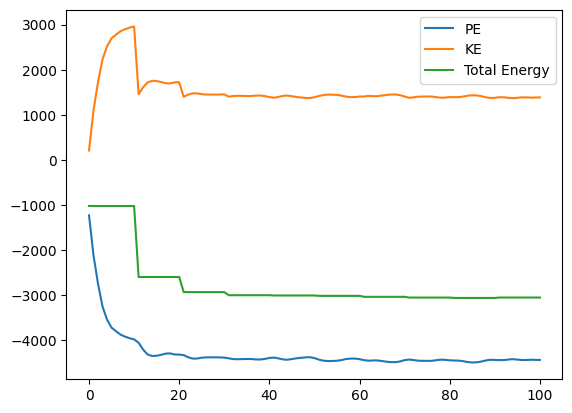

In [50]:
# PLOT FROM MD FUNCTION OUTPUT
import matplotlib.pyplot as plt
print("Final Temperature: ", temp(vel=vel_final,N=N))
plt.plot(PEs, label = 'PE')
plt.plot(KEs, label = 'KE')
plt.plot(TEs, label = 'Total Energy')
plt.legend()
plt.show()


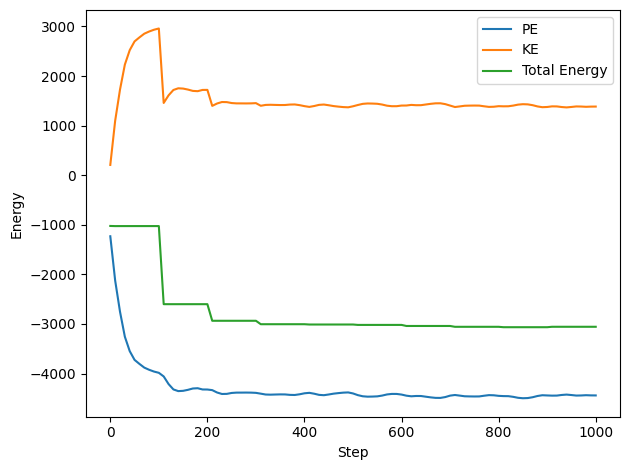

In [3]:
# UNLOAD DATA FROM NPZ AND PLOT 
##### INSERT FILE PATH #####
import matplotlib.pyplot as plt

file_path = 'MD_Final_Thermalized_2025-09-30_18:22:20.npz'
def unload_from_npz(path):

  with np.load(path, allow_pickle=True) as d:
      pos = d["pos"]         
      vel = d["vel"]          
      steps = d["steps"] 

    
      PEs, KEs, TEs = d["PEs"], d["KEs"], d["TEs"]
      Forces = d["Forces"]
  return pos, vel, steps, Forces,PEs, KEs,TEs


pos_file, vel_file, steps_file, Forces,PEs, KEs,TEs  = unload_from_npz(file_path)

plt.figure()
plt.plot(steps_file, PEs, label='PE')
plt.plot(steps_file, KEs, label='KE')
plt.plot(steps_file, TEs, label='Total Energy')
plt.xlabel('Step')
plt.ylabel('Energy')
plt.legend()
plt.tight_layout()
plt.show()



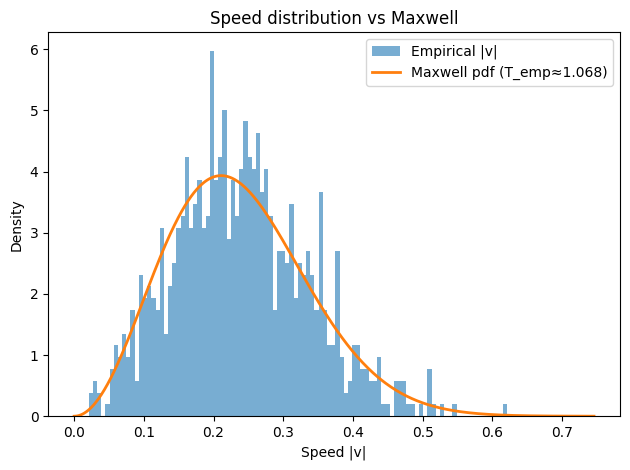

T_est  = 1.068409
<v^2>  (empirical) = 0.066776
<v^2> = 3sigma^2   (theory)    = 0.066776  (sigma^2 = T/48)


In [52]:
# COMPARE EMPERICAL SPEED DISTRIBUTION TO MB 
def MB_speed(vel, T):
    return np.sqrt(2.0/np.pi) * (48.0/T)**1.5 * vel*vel * np.exp(-24.0*vel*vel/T)

def plot_speed_hist_vs_maxwell(vel, bins=100):



    speeds = np.linalg.norm(vel, axis=1)
    T = temp(vel,N)  # already removed COM if requested

 
    fig, ax = plt.subplots()

    ax.hist(speeds, bins=bins, density=True, alpha=0.6, label="Empirical |v|")

    sigma2 = T / 48.0
    vmax = max(speeds.max(), 5.0 * np.sqrt(sigma2))
    vgrid = np.linspace(0.0, vmax, 500)
    ax.plot(vgrid, MB_speed(vgrid, T), lw=2, label=f"Maxwell pdf (T_emp≈{T:.3f})")

    ax.set_xlabel("Speed |v|")
    ax.set_ylabel("Density")
    ax.set_title("Speed distribution vs Maxwell")
    ax.legend()
    plt.tight_layout()
    
    plt.show()
    v2_emp = np.mean(speeds**2)
    print(f"T_est  = {T:.6f}")
    print(f"<v^2>  (empirical) = {v2_emp:.6f}")
    print(f"<v^2> = 3sigma^2   (theory)    = {3.0*sigma2:.6f}  (sigma^2 = T/48)")
    return 
plot_speed_hist_vs_maxwell(vel_file[-1])

|r_ij| From 0 to sqrt(3)L/2 (L=10.482965576835586) 
There is peak at 1sigma and smaller one 2sigma indicating gridlike pattern 


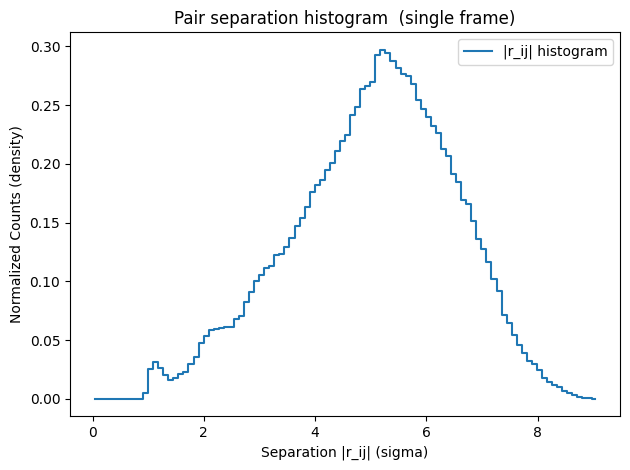

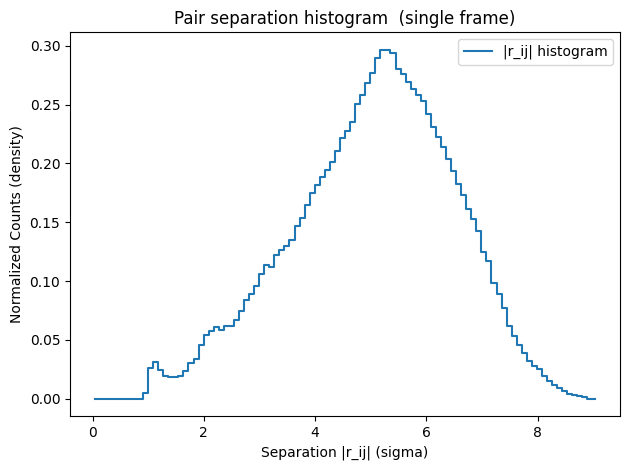

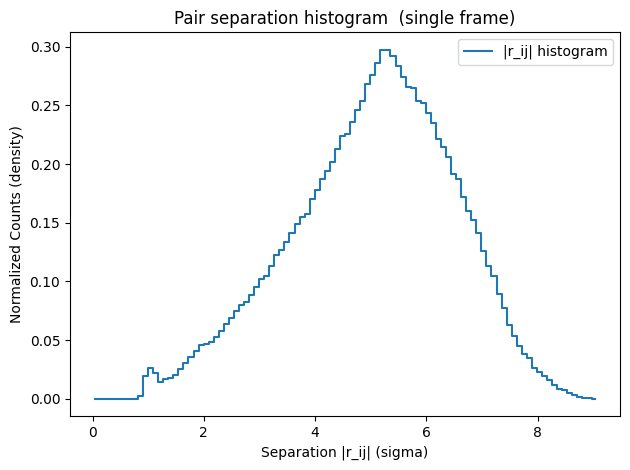

In [90]:
# HISTOGRAM OF PARTICLE SEPEARATION AT THREE POINTS IN SIMULATION. 

def plot_separation_hist_one(pos, L, bins=100):

    pos = np.asarray(pos, dtype=float)
    N = pos.shape[0]

    d = r_ij_matrix(pos, L)  
    iu = np.triu_indices(N, k=1)  
    r = np.linalg.norm(d[iu], axis=1)
    rL = r
    edges = np.linspace(0.0, L*np.sqrt(3)/2, bins + 1)
    counts, _ = np.histogram(rL, bins=edges, density = True)
    centers = 0.5 * (edges[:-1] + edges[1:])

   
    plt.figure()
    plt.plot(centers, counts, drawstyle="steps-mid", label="|r_ij| histogram")
    plt.xlabel("Separation |r_ij| (sigma)")
    plt.ylabel("Normalized Counts (density)")
    plt.title("Pair separation histogram  (single frame)")
    plt.legend()
    plt.tight_layout()
    plt.show()
    return 
print(f"""|r_ij| From 0 to sqrt(3)L/2 (L={L}) 
There is peak at 1sigma and smaller one 2sigma indicating gridlike pattern """)

plot_separation_hist_one(pos_file[-1],L)
plot_separation_hist_one(pos_file[-50],L)
plot_separation_hist_one(pos_file[-100],L)





step 0  PE=-4441.260213  KE= 1384.658443  E=-3056.601770
step 1  PE=-4440.396708  KE= 1383.794835  E=-3056.601873
step 2  PE=-4439.325102  KE= 1382.723383  E=-3056.601719
step 3  PE=-4438.050062  KE= 1381.448746  E=-3056.601316
step 4  PE=-4436.580348  KE= 1379.979679  E=-3056.600669
step 5  PE=-4434.928674  KE= 1378.328880  E=-3056.599794
step 6  PE=-4433.111487  KE= 1376.512784  E=-3056.598703
step 7  PE=-4431.148735  KE= 1374.551321  E=-3056.597414
step 8  PE=-4429.063567  KE= 1372.467622  E=-3056.595945
step 9  PE=-4426.881987  KE= 1370.287669  E=-3056.594318
step 10  PE=-4424.632444  KE= 1368.039879  E=-3056.592565
step 11  PE=-4422.345303  KE= 1365.754581  E=-3056.590722
step 12  PE=-4420.052237  KE= 1363.463402  E=-3056.588835
step 13  PE=-4417.785468  KE= 1361.198508  E=-3056.586960
step 14  PE=-4415.576888  KE= 1358.991733  E=-3056.585155
step 15  PE=-4413.457126  KE= 1356.873643  E=-3056.583483
step 16  PE=-4411.454553  KE= 1354.872551  E=-3056.582002
step 17  PE=-4409.594351

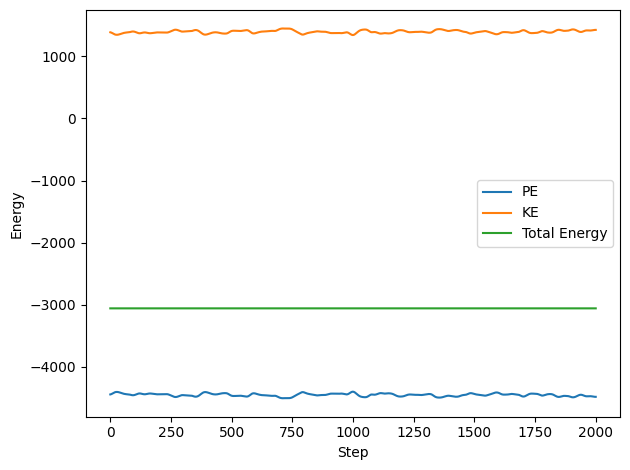

In [7]:
# 500 additional steps from file (after thermalization) to get Final Temeperature and Pressure (Virial theorem)
N = 864
rho = 0.75
L = (N / rho) ** (1/3)
def virial(pos, forces):
    assert pos.shape == forces.shape and pos.shape[1] == 3
    return float(np.sum(pos * forces))  
def pressure_from_virial(G, N, L, T):
    V = float(L)**3
    rho = N / V
    return rho * T + (G / (3.0 * V))

add_steps = 2000
file_name = "MD_results_for_stat_analysis"
pos_final,vel_final,Forces, PEs,KEs,TEs,steps =  md_verlet(pos_file[-1],vel_file[-1],L,n_steps=add_steps,rescale=False,saving=True,save_interval=1,file_name=file_name,verbose=True)


Ts, Ps = [],[]
for i in range(len(pos_final)):
    T = temp(vel=vel_final[i],N=N)
    Ts.append(T)
    G = virial(pos_final[i],Forces[i])
    P = pressure_from_virial(G,N,L,T)
    Ps.append(P)
    # print(f"step {i*10} T: {T} P: {P}")
print(f"Final Temeperature = {np.mean(Ts)} +- {np.std(Ts)} after 500 additional steps (50 measurements)")
print(f"Final Pressure = {np.mean(Ps)} +- {np.std(Ps)} after 500 additional steps (50 measurements) ")
print("Error bars are simple standard deviation (NOT autocorrelation correectd)")




plt.figure()
plt.plot(steps, PEs, label='PE')
plt.plot(steps, KEs, label='KE')
plt.plot(steps, TEs, label='Total Energy')
plt.xlabel('Step')
plt.ylabel('Energy')
plt.legend()
plt.tight_layout()
plt.show()